# Molecular Property Prediction — Random Forest vs Graph Neural Network

**Dataset:** Delaney ESOL (1 128 small organic molecules with measured aqueous solubility, `logS` in log mol/L).

**Goal:** predict `logS` from a molecule's structure alone, two different ways, and compare them honestly on a held-out test set.

| | Approach A | Approach B |
|---|---|---|
| Representation | Morgan fingerprint (2048 bits, radius 2) | Molecular graph (atoms = nodes, bonds = edges) |
| Model | Random Forest (+ GridSearchCV) | 3-layer GIN with edge features + mean pooling + MLP |
| Uncertainty | Spread across trees | Monte-Carlo dropout |
| Explainability | SHAP on fingerprint bits | — |

> **If you are new to cheminformatics:** a molecule is handed to us as a **SMILES** string (e.g. `CC(=O)Oc1ccccc1C(=O)O` is aspirin). It is a compact text encoding of a graph: letters are atoms, bonds are implicit between neighbours, `=` is a double bond, lowercase letters are aromatic atoms, parentheses are branches and matching digits close rings. RDKit parses SMILES into a `Mol` object we can walk, featurise and embed in 3D.

The notebook ends by writing `export_results.json` and `coords.json`, which power the interactive `index.html`.

## 1. Setup & imports

In [1]:
import os, json, math, time, warnings, random
import sys
# shap.TreeExplainer probes for `transformers`, which in turn imports TensorFlow if installed and floods stderr
# with oneDNN/absl log lines. Neither library is used here, so we make the probe fail fast.
for _m in ("transformers", "tensorflow"):
    sys.modules.setdefault(_m, None)
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Draw, Descriptors, Crippen, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool

import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything()
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))
DEVICE = torch.device("cpu")          # CPU-only by design

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
TARGET = "measured log solubility in mols per litre"

print("torch", torch.__version__, "| rdkit", Chem.rdBase.rdkitVersion, "| shap", shap.__version__, "| device", DEVICE)

torch 2.11.0+cu130 | rdkit 2026.09.2 | shap 0.54.1 | device cpu


## 2. Data loading & EDA

ESOL (Delaney 2004) is the standard "hello world" of molecular property prediction. Each row is one compound with its **measured** aqueous solubility, `logS = log10(mol / L)`. Values span ~ -11 (practically insoluble, e.g. large chlorinated aromatics) to ~ +1.6 (miscible, e.g. small alcohols).

We load the DeepChem-processed CSV (cached locally in `data/`; downloaded if missing — `deepchem.molnet.load_delaney()` provides the same file).

In [2]:
CSV = DATA_DIR / "delaney-processed.csv"
URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
if not CSV.exists():
    import urllib.request
    urllib.request.urlretrieve(URL, CSV)

df = pd.read_csv(CSV)
df = df.rename(columns={"Compound ID": "name", TARGET: "logS"})
df["smiles"] = df["smiles"].str.strip()
df["name"] = df["name"].str.strip()

# Parse every SMILES with RDKit and keep a canonical form so duplicates can be found
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
assert df["mol"].notna().all(), "unparseable SMILES found"
df["canon"] = df["mol"].apply(lambda m: Chem.MolToSmiles(m, isomericSmiles=False))
n_before = len(df)
df = df.drop_duplicates("canon").reset_index(drop=True)
print(f"{n_before} rows → {len(df)} unique molecules")
df[["name", "smiles", "logS", "Molecular Weight"]].head()

1128 rows → 1115 unique molecules


,name,smiles,logS,Molecular Weight
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,457.432
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30,201.225
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06,152.237
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,278.354
4,Thiophene,c1ccsc1,-1.33,84.143


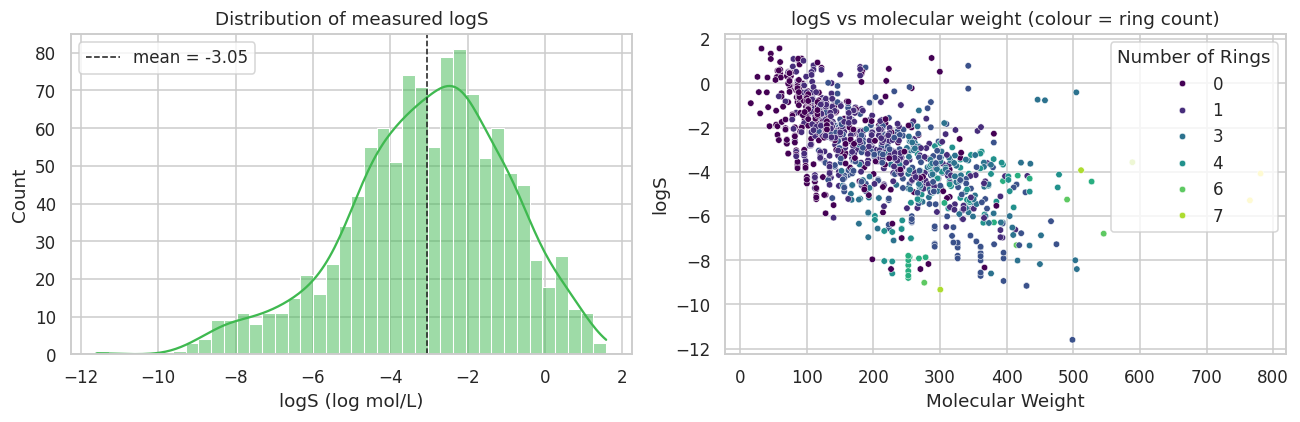

count    1115.000
mean       -3.054
std         2.094
min       -11.600
25%        -4.312
50%        -2.878
75%        -1.600
max         1.580
Name: logS, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["logS"], bins=40, kde=True, ax=axes[0], color="#3fb950")
axes[0].set(title="Distribution of measured logS", xlabel="logS (log mol/L)")
axes[0].axvline(df["logS"].mean(), ls="--", c="k", lw=1, label=f"mean = {df['logS'].mean():.2f}")
axes[0].legend()
sns.scatterplot(data=df, x="Molecular Weight", y="logS", hue="Number of Rings", palette="viridis", s=18, ax=axes[1])
axes[1].set(title="logS vs molecular weight (colour = ring count)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_logS.png"); plt.show()
df["logS"].describe().round(3)

A quick look at the extremes makes the chemistry intuitive: the most soluble compounds are tiny and polar, the least soluble are big, flat and greasy (many aromatic rings, halogens, no H-bond donors).

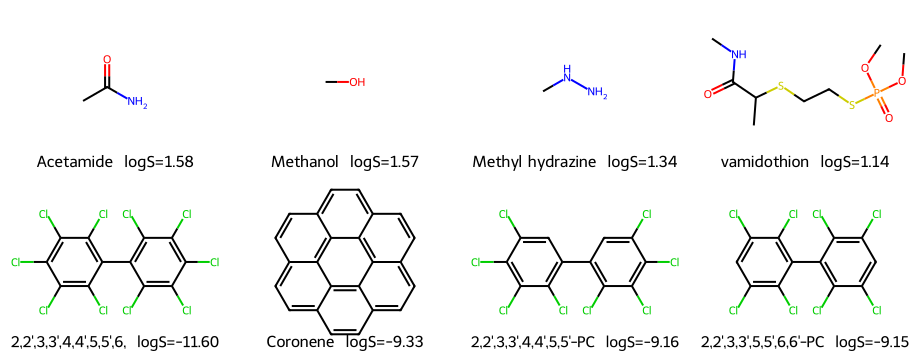

In [4]:
extremes = pd.concat([df.nlargest(4, "logS"), df.nsmallest(4, "logS")])
Draw.MolsToGridImage(
    list(extremes["mol"]), molsPerRow=4, subImgSize=(230, 180),
    legends=[f"{n[:22]}  logS={s:.2f}" for n, s in zip(extremes["name"], extremes["logS"])],
)

### Showcase molecules

The frontend highlights ten familiar molecules. Five are in ESOL; for the other five we use literature solubilities (AqSolDB / Yalkowsky *Handbook of Aqueous Solubility Data*), tagged `source = "literature"` in the export so they are never confused with dataset values. Any showcase molecule that *is* in ESOL is forced into the **test** split so its prediction is a genuine out-of-sample prediction.

In [5]:
SHOWCASE = {
    # name        : (SMILES, literature logS used only if the molecule is absent from ESOL)
    "water":       ("O",                                              1.74),   # log10(55.5 mol/L): pure water is its own solvent
    "ethanol":     ("CCO",                                            None),
    "benzene":     ("c1ccccc1",                                       None),
    "aspirin":     ("CC(=O)Oc1ccccc1C(=O)O",                         -1.72),   # ~3.4 g/L at 25 °C
    "caffeine":    ("Cn1cnc2c1c(=O)n(C)c(=O)n2C",                    None),
    "ibuprofen":   ("CC(C)Cc1ccc(cc1)C(C)C(=O)O",                    -3.99),   # ~21 mg/L
    "glucose":     ("OCC1OC(O)C(O)C(O)C1O",                           None),
    "penicillin":  ("CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O",    -1.80),   # penicillin G free acid, ~5 g/L (AqSolDB -1.8)
    "dopamine":    ("NCCc1ccc(O)c(O)c1",                             -0.13),   # free base, AqSolDB
    "paracetamol": ("CC(=O)Nc1ccc(O)cc1",                             None),   # ESOL name: p-Hydroxyacetanilide
}
canon_to_idx = {c: i for i, c in enumerate(df["canon"])}
showcase_rows = []
for name, (smi, lit) in SHOWCASE.items():
    canon = Chem.MolToSmiles(Chem.MolFromSmiles(smi), isomericSmiles=False)
    idx = canon_to_idx.get(canon)
    showcase_rows.append(dict(name=name, smiles=smi, canon=canon, in_esol=idx is not None,
                              esol_idx=idx, actual=df.loc[idx, "logS"] if idx is not None else lit,
                              source="dataset" if idx is not None else "literature"))
showcase = pd.DataFrame(showcase_rows)
showcase[["name", "smiles", "in_esol", "actual", "source"]]

,name,smiles,in_esol,actual,source
0,water,O,False,1.740,literature
1,ethanol,CCO,True,1.100,dataset
2,benzene,c1ccccc1,True,-1.640,dataset
3,aspirin,CC(=O)Oc1ccccc1C(=O)O,False,-1.720,literature
4,caffeine,Cn1cnc2c1c(=O)n(C)c(=O)n2C,True,-0.876,dataset
5,ibuprofen,CC(C)Cc1ccc(cc1)C(C)C(=O)O,False,-3.990,literature
6,glucose,OCC1OC(O)C(O)C(O)C1O,True,0.740,dataset
7,penicillin,CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O,False,-1.800,literature
8,dopamine,NCCc1ccc(O)c(O)c1,False,-0.130,literature
9,paracetamol,CC(=O)Nc1ccc(O)cc1,True,-1.030,dataset


### Train / validation / test split

80 / 10 / 10 random split (seed 42). The validation set is only used by the GNN for early stopping (the RF uses internal cross-validation instead), so both models see exactly the same training molecules and are scored on exactly the same test molecules.

In [6]:
forced_test = sorted(int(i) for i in showcase["esol_idx"].dropna())
rest = [i for i in range(len(df)) if i not in forced_test]
train_idx, tmp_idx = train_test_split(rest, test_size=0.20, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, random_state=SEED)
test_idx = sorted(test_idx + forced_test)
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}  (incl. {len(forced_test)} forced showcase molecules)")
y = df["logS"].values.astype(np.float32)

train 888 | val 111 | test 116  (incl. 5 forced showcase molecules)


## 3. Approach A — Morgan fingerprints + Random Forest

**Intuition.** A Morgan (a.k.a. ECFP) fingerprint describes a molecule as a *bag of circular substructures*. For every atom we look at its neighbourhood up to `radius` bonds away (radius 2 ⇒ "ECFP4"), hash that environment to an integer and set the corresponding bit in a 2048-bit vector. Two molecules sharing many bits share many local motifs — carboxylic acids, aromatic rings, chlorinated carbons, …

The result is a fixed-length, sparse binary vector — exactly what classical ML wants. A Random Forest is a natural fit: it handles thousands of binary features, needs no scaling and gives a free uncertainty estimate (disagreement between trees).

In [7]:
N_BITS, RADIUS = 2048, 2
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=RADIUS, fpSize=N_BITS)

def morgan_fp(mol) -> np.ndarray:
    return fp_gen.GetFingerprintAsNumPy(mol).astype(np.float32)   # float, not uint8 — SHAP TreeExplainer needs it

X = np.stack([morgan_fp(m) for m in df["mol"]])
print("fingerprint matrix:", X.shape, "| mean bits set per molecule:", X.sum(1).mean().round(1))
X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

fingerprint matrix: (1115, 2048) | mean bits set per molecule: 21.5


A small but meaningful grid (3-fold CV on the training set, scored by negative RMSE). `max_features` is the most influential knob for sparse fingerprints; `min_samples_leaf` controls smoothing.

In [8]:
param_grid = {
    "n_estimators":     [300, 600],
    "max_features":     ["sqrt", 0.2],
    "min_samples_leaf": [1, 2],
}
rf_base = RandomForestRegressor(random_state=SEED, n_jobs=-1)
t0 = time.time()
grid = GridSearchCV(rf_base, param_grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=1, verbose=0)
grid.fit(X_train, y_train)
print(f"grid search done in {time.time()-t0:.0f}s")
print("best params:", grid.best_params_, "| CV RMSE:", -grid.best_score_.round(3))
rf = grid.best_estimator_
pd.DataFrame(grid.cv_results_)[["param_n_estimators", "param_max_features", "param_min_samples_leaf", "mean_test_score", "rank_test_score"]] \
  .sort_values("rank_test_score").head(8).assign(mean_test_score=lambda d: -d.mean_test_score)

grid search done in 7s
best params: {'max_features': 0.2, 'min_samples_leaf': 1, 'n_estimators': 600} | CV RMSE: 1.282


,param_n_estimators,param_max_features,param_min_samples_leaf,mean_test_score,rank_test_score
5,600,0.2,1,1.281663,1
4,300,0.2,1,1.282405,2
1,600,sqrt,1,1.297627,3
0,300,sqrt,1,1.300010,4
7,600,0.2,2,1.318056,5
6,300,0.2,2,1.318821,6
3,600,sqrt,2,1.486830,7
2,300,sqrt,2,1.489474,8


In [9]:
def metrics(y_true, y_pred) -> dict:
    return {"rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "mae":  float(mean_absolute_error(y_true, y_pred)),
            "r2":   float(r2_score(y_true, y_pred))}

def rf_predict_with_std(model, Xq):
    per_tree = np.stack([t.predict(Xq) for t in model.estimators_])  # (n_trees, n_samples)
    return per_tree.mean(0), per_tree.std(0)

rf_test_pred, rf_test_std = rf_predict_with_std(rf, X_test)
rf_perf = metrics(y_test, rf_test_pred)
print({k: round(v, 3) for k, v in rf_perf.items()})

{'rmse': 1.181, 'mae': 0.903, 'r2': 0.696}


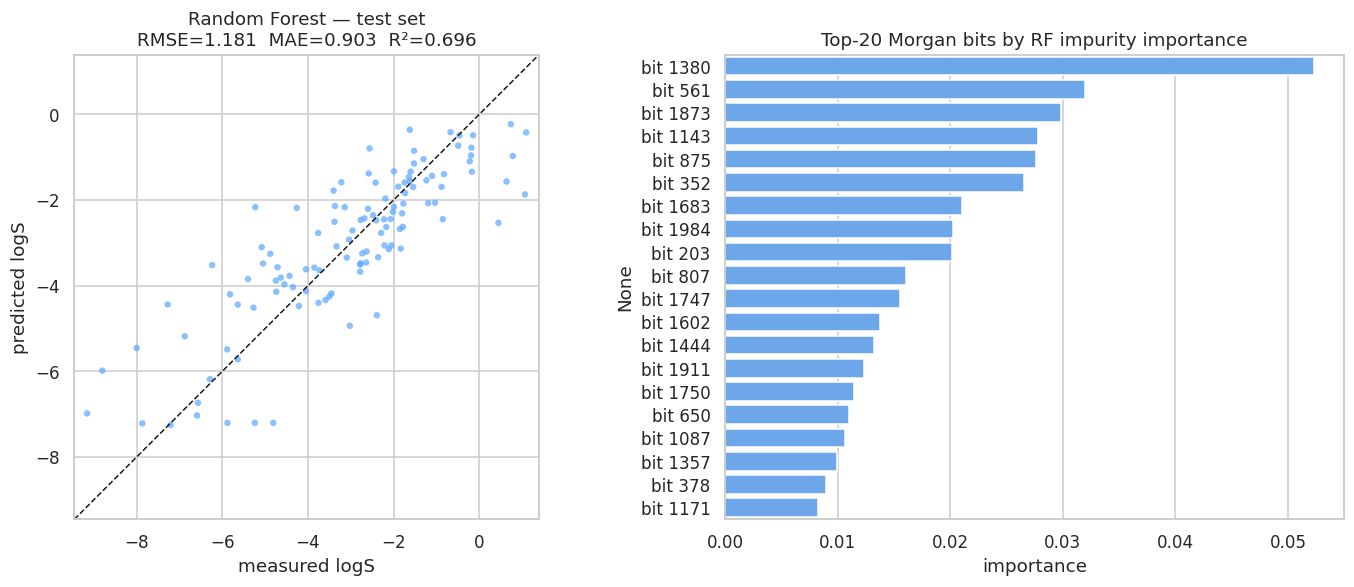

In [10]:
def parity_plot(ax, y_true, y_pred, title, color):
    lim = [min(y_true.min(), y_pred.min()) - 0.3, max(y_true.max(), y_pred.max()) + 0.3]
    ax.plot(lim, lim, "k--", lw=1)
    ax.scatter(y_true, y_pred, s=18, alpha=0.7, color=color, edgecolor="none")
    m = metrics(y_true, y_pred)
    ax.set(xlim=lim, ylim=lim, xlabel="measured logS", ylabel="predicted logS",
           title=f"{title}\nRMSE={m['rmse']:.3f}  MAE={m['mae']:.3f}  R²={m['r2']:.3f}")
    ax.set_aspect("equal")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
parity_plot(axes[0], y_test, rf_test_pred, "Random Forest — test set", "#58a6ff")
imp = pd.Series(rf.feature_importances_, index=[f"bit {i}" for i in range(N_BITS)]).nlargest(20)
sns.barplot(x=imp.values, y=imp.index, ax=axes[1], color="#58a6ff")
axes[1].set(title="Top-20 Morgan bits by RF impurity importance", xlabel="importance")
plt.tight_layout(); plt.savefig(FIG_DIR / "rf_parity_importance.png"); plt.show()

### SHAP explainability

Impurity importance says *which* bits matter; SHAP says **in which direction** and **for which molecules**. `TreeExplainer` computes exact Shapley values for tree ensembles (here in *interventional* mode against a 100-molecule training background, so each value is the bit's contribution relative to a typical training molecule). In the beeswarm, each dot is one test molecule; red = bit is set (substructure present), blue = not set; x position = how much that bit pushed the predicted logS up or down.

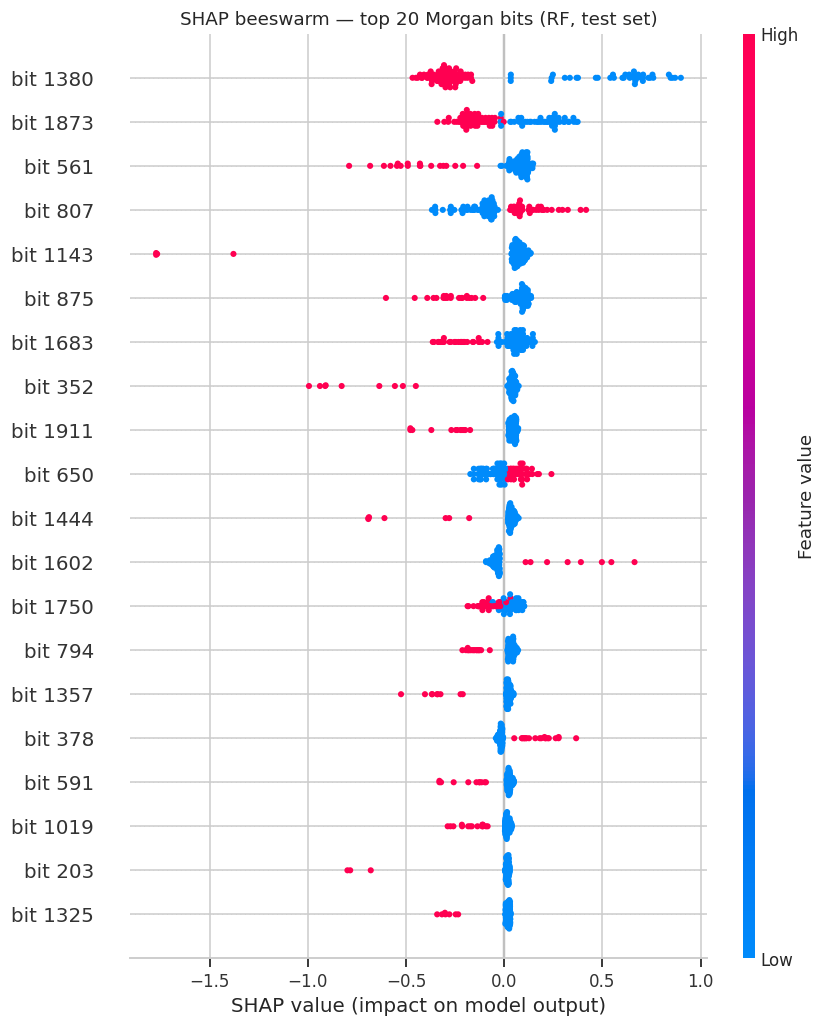

In [11]:
# Interventional SHAP with a training-set background: exact Shapley values w.r.t. that background.
# (The default "tree_path_dependent" algorithm is numerically unstable on the very deep, fully-grown
#  trees an RF builds on 2048 sparse bits — depth > 60 here — so we avoid it.)
background = shap.sample(X_train, 100, random_state=SEED)
explainer = shap.TreeExplainer(rf, data=background, feature_perturbation="interventional")
shap_values = explainer.shap_values(X_test)
assert np.abs(explainer.expected_value + shap_values.sum(1) - rf.predict(X_test)).max() < 1e-3  # additivity sanity check
feature_names = [f"bit {i}" for i in range(N_BITS)]
shap.summary_plot(shap_values, X_test, feature_names=feature_names, max_display=20, show=False)
plt.title("SHAP beeswarm — top 20 Morgan bits (RF, test set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_beeswarm.png", bbox_inches="tight"); plt.show()

A fingerprint bit is just a hash, so to *read* the beeswarm we map the top bits back to the chemical substructure they encode (RDKit keeps the atom environment that produced each bit).

In [12]:
mean_abs = np.abs(shap_values).mean(0)
top_bits = np.argsort(mean_abs)[::-1][:10]
ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()

def describe_bit(bit):
    # find a molecule (prefer one in train) that sets this bit and extract the substructure
    for i in train_idx + test_idx:
        if X[i, bit]:
            mol = df.loc[i, "mol"]
            fp_gen.GetFingerprint(mol, additionalOutput=ao)
            atom, rad = ao.GetBitInfoMap()[bit][0]
            if rad == 0:
                frag = Chem.MolFragmentToSmiles(mol, atomsToUse=[atom], allHsExplicit=True)  # e.g. [cH] aromatic CH, [CH3] methyl
            else:
                env = Chem.FindAtomEnvironmentOfRadiusN(mol, rad, atom)
                atoms_in_env = sorted({mol.GetBondWithIdx(b).GetBeginAtomIdx() for b in env} | {mol.GetBondWithIdx(b).GetEndAtomIdx() for b in env})
                frag = Chem.MolFragmentToSmiles(mol, atomsToUse=atoms_in_env, bondsToUse=list(env), rootedAtAtom=atom, allHsExplicit=True)
            return dict(bit=int(bit), mean_abs_shap=float(mean_abs[bit]),
                        direction="↑ logS (more soluble)" if np.corrcoef(X_test[:, bit], shap_values[:, bit])[0, 1] > 0 else "↓ logS (less soluble)",
                        radius=int(rad), fragment=frag, example=df.loc[i, "name"])
    return dict(bit=int(bit))

bit_table = pd.DataFrame([describe_bit(b) for b in top_bits])
bit_table

,bit,mean_abs_shap,direction,radius,fragment,example
0,1380,0.391166,↓ logS (less soluble),0,[c],Benzo(e)pyrene
1,1873,0.174872,↓ logS (less soluble),0,[CH],triforine
2,561,0.144877,↓ logS (less soluble),1,[Cl][c],DDT
3,807,0.130524,↑ logS (more soluble),0,[C],Isopropyl acetate
4,1143,0.129068,↓ logS (less soluble),2,[CH2]([CH2][CH2])[CH2][CH2],1-Decanol
5,875,0.120270,↓ logS (less soluble),1,[cH]([c])[c],"2,2,4,6,6'-PCB"
6,1683,0.104629,↓ logS (less soluble),0,[Cl],triforine
7,352,0.098712,↓ logS (less soluble),1,[c](-[c])([cH])[c],Fluridone
8,1911,0.070336,↓ logS (less soluble),1,[CH2]([CH2])[CH2],1-Decanol
9,650,0.068970,↑ logS (more soluble),0,[O],triforine


legend order: ['bit 1380', 'bit 1873', 'bit 561', 'bit 807', 'bit 1143', 'bit 875']


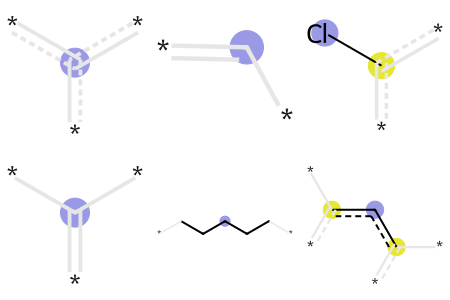

In [13]:
# Draw the atom environments of the top-6 SHAP bits
imgs, legends = [], []
for b in top_bits[:6]:
    for i in train_idx:
        if X[i, b]:
            mol = df.loc[i, "mol"]; fp_gen.GetFingerprint(mol, additionalOutput=ao)
            imgs.append(Draw.DrawMorganBit(mol, int(b), ao.GetBitInfoMap(), useSVG=False)); legends.append(f"bit {b}")
            break
from PIL import Image
w, h = imgs[0].size
sheet = Image.new("RGB", (w * 3, h * 2), "white")
for k, im in enumerate(imgs):
    sheet.paste(im, ((k % 3) * w, (k // 3) * h))
sheet.save(FIG_DIR / "shap_top_bits.png")
print("legend order:", legends)
sheet

## 4. Approach B — Graph Neural Network

**Intuition.** Fingerprints throw away the global connectivity and compress everything into hashed bits. A GNN instead works directly on the molecular graph. Every atom starts with a feature vector (element, degree, hybridisation, aromaticity, charge, attached hydrogens). At each *message-passing* layer an atom updates its vector by aggregating its neighbours' vectors — after 3 layers each atom "knows" its 3-bond neighbourhood, much like a radius-3 Morgan environment but **learned** instead of hashed. A global mean pool averages all atom vectors into one molecule vector, and an MLP maps that to `logS`.

We use **GIN** layers with edge features (`GINEConv`), which are provably as expressive as the Weisfeiler–Lehman graph isomorphism test, so they distinguish more structures than plain GCN.

In [14]:
ATOM_LIST   = [1, 5, 6, 7, 8, 9, 14, 15, 16, 17, 35, 53]        # H B C N O F Si P S Cl Br I  (+ "other")
HYBRID_LIST = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3,
               Chem.HybridizationType.SP3D, Chem.HybridizationType.SP3D2]
BOND_LIST   = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def onehot(value, choices, with_other=True):
    v = [float(value == c) for c in choices]
    if with_other: v.append(float(value not in choices))
    return v

def atom_features(a):
    return (onehot(a.GetAtomicNum(), ATOM_LIST) +            # 13
            onehot(a.GetDegree(), [0, 1, 2, 3, 4, 5]) +       # 7
            onehot(a.GetHybridization(), HYBRID_LIST) +       # 6
            [float(a.GetIsAromatic())] +                      # 1
            onehot(a.GetFormalCharge(), [-1, 0, 1]) +         # 4
            onehot(a.GetTotalNumHs(), [0, 1, 2, 3, 4]))       # 6   → 37 dims

def bond_features(b):
    return (onehot(b.GetBondType(), BOND_LIST, with_other=False) +   # 4
            [float(b.GetIsConjugated()), float(b.IsInRing())])        # 2  → 6 dims

def mol_to_graph(mol, y_val=None):
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    src, dst, eattr = [], [], []
    for b in mol.GetBonds():
        i, j, f = b.GetBeginAtomIdx(), b.GetEndAtomIdx(), bond_features(b)
        src += [i, j]; dst += [j, i]; eattr += [f, f]            # undirected → both directions
    edge_index = torch.tensor([src, dst], dtype=torch.long) if src else torch.zeros((2, 0), dtype=torch.long)
    edge_attr  = torch.tensor(eattr, dtype=torch.float) if eattr else torch.zeros((0, 6))
    d = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
    if y_val is not None: d.y = torch.tensor([y_val], dtype=torch.float)
    return d

graphs = [mol_to_graph(m, float(t)) for m, t in zip(df["mol"], y)]
NODE_DIM, EDGE_DIM = graphs[0].x.shape[1], graphs[0].edge_attr.shape[1]
print(f"node features: {NODE_DIM} | edge features: {EDGE_DIM}")
print(graphs[0], "←", df.loc[0, "name"])

node features: 37 | edge features: 6
Data(x=[32, 37], edge_index=[2, 68], edge_attr=[68, 6], y=[1]) ← Amigdalin


In [15]:
class GINNet(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden=128, n_layers=3, dropout=0.2):
        super().__init__()
        self.node_enc = nn.Linear(node_dim, hidden)
        self.edge_enc = nn.Linear(edge_dim, hidden)
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Linear(hidden, hidden))
            self.convs.append(GINEConv(mlp, train_eps=True))
            self.bns.append(nn.BatchNorm1d(hidden))
        self.dropout = dropout
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))

    def forward(self, data):
        h = self.node_enc(data.x); e = self.edge_enc(data.edge_attr)
        for conv, bn in zip(self.convs, self.bns):
            h = h + F.dropout(F.relu(bn(conv(h, data.edge_index, e))), self.dropout, self.training)  # residual
        g = global_mean_pool(h, data.batch)
        return self.head(g).squeeze(-1)

model = GINNet(NODE_DIM, EDGE_DIM)
print(f"{sum(p.numel() for p in model.parameters()):,} trainable parameters")

131,204 trainable parameters


Training details: the target is standardised (zero mean / unit variance on the training set) so the loss scale is well-behaved; Adam with `ReduceLROnPlateau` on validation RMSE; early stopping restores the weights of the best validation epoch. CPU training on ~900 small graphs takes a few seconds per epoch.

In [16]:
y_mean, y_std = float(y[train_idx].mean()), float(y[train_idx].std())
train_loader = DataLoader([graphs[i] for i in train_idx], batch_size=32, shuffle=True)
val_loader   = DataLoader([graphs[i] for i in val_idx],   batch_size=128)
test_loader  = DataLoader([graphs[i] for i in test_idx],  batch_size=128)

@torch.no_grad()
def predict(model, loader, mc_samples=0):
    '''Returns (mean, std) in original logS units. mc_samples>0 → MC-dropout uncertainty.'''
    if mc_samples == 0:
        model.eval(); out = torch.cat([model(b.to(DEVICE)) for b in loader]) * y_std + y_mean
        return out.numpy(), np.zeros(len(out))
    model.eval()
    for m in model.modules():                      # keep BatchNorm frozen, only dropout stochastic
        if isinstance(m, nn.Dropout): m.train()
    model.dropout_training = True
    samples = []
    for _ in range(mc_samples):
        preds = []
        for b in loader:
            h = model.node_enc(b.x); e = model.edge_enc(b.edge_attr)
            for conv, bn in zip(model.convs, model.bns):
                h = h + F.dropout(F.relu(bn(conv(h, b.edge_index, e))), model.dropout, True)
            preds.append(model.head(global_mean_pool(h, b.batch)).squeeze(-1))
        samples.append(torch.cat(preds) * y_std + y_mean)
    S = torch.stack(samples).numpy()
    model.eval()
    return S.mean(0), S.std(0)

def train_gnn(model, train_loader, val_loader, max_epochs=300, patience=30, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=10, min_lr=1e-5)
    best, best_state, bad, history = float("inf"), None, 0, []
    for epoch in range(1, max_epochs + 1):
        model.train(); tot = 0.0
        for b in train_loader:
            opt.zero_grad()
            loss = F.mse_loss(model(b), (b.y - y_mean) / y_std)
            loss.backward(); opt.step(); tot += loss.item() * b.num_graphs
        train_rmse = math.sqrt(tot / len(train_loader.dataset)) * y_std
        val_pred, _ = predict(model, val_loader)
        val_rmse = math.sqrt(mean_squared_error(y[val_idx], val_pred))
        sched.step(val_rmse)
        history.append(dict(epoch=epoch, train_rmse=train_rmse, val_rmse=val_rmse, lr=opt.param_groups[0]["lr"]))
        if val_rmse < best - 1e-4:
            best, bad, best_state = val_rmse, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose and (epoch % 20 == 0 or epoch == 1):
            print(f"epoch {epoch:3d} | train RMSE {train_rmse:.3f} | val RMSE {val_rmse:.3f} | lr {opt.param_groups[0]['lr']:.1e}")
        if bad >= patience:
            if verbose: print(f"early stopping at epoch {epoch}; best val RMSE {best:.3f}")
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

seed_everything()
model = GINNet(NODE_DIM, EDGE_DIM).to(DEVICE)
t0 = time.time()
hist = train_gnn(model, train_loader, val_loader)
print(f"training time {time.time()-t0:.0f}s")

epoch   1 | train RMSE 1.749 | val RMSE 1.540 | lr 1.0e-03


epoch  20 | train RMSE 0.733 | val RMSE 0.729 | lr 1.0e-03


epoch  40 | train RMSE 0.656 | val RMSE 0.648 | lr 5.0e-04


epoch  60 | train RMSE 0.557 | val RMSE 0.661 | lr 2.5e-04


early stopping at epoch 69; best val RMSE 0.591
training time 9s


{'rmse': 0.584, 'mae': 0.448, 'r2': 0.926}


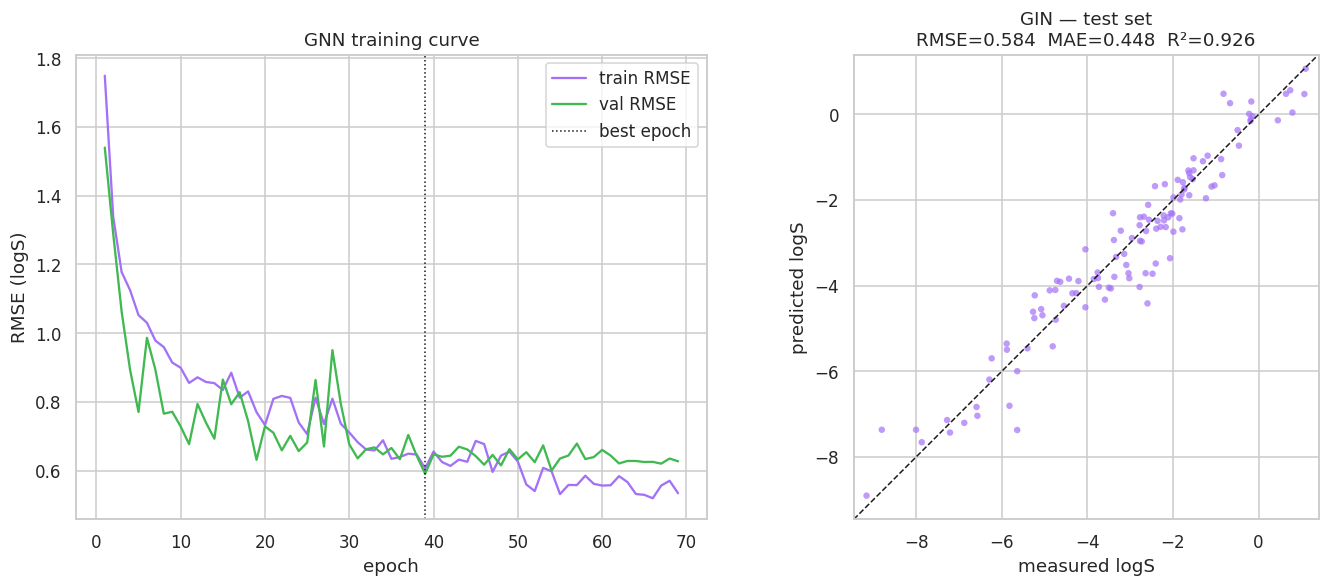

In [17]:
gnn_test_pred, gnn_test_std = predict(model, test_loader, mc_samples=30)
gnn_perf = metrics(y_test, gnn_test_pred)
print({k: round(v, 3) for k, v in gnn_perf.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].plot(hist["epoch"], hist["train_rmse"], label="train RMSE", color="#a371f7")
axes[0].plot(hist["epoch"], hist["val_rmse"], label="val RMSE", color="#3fb950")
axes[0].axvline(hist["val_rmse"].idxmin() + 1, ls=":", c="k", lw=1, label="best epoch")
axes[0].set(title="GNN training curve", xlabel="epoch", ylabel="RMSE (logS)"); axes[0].legend()
parity_plot(axes[1], y_test, gnn_test_pred, "GIN — test set", "#a371f7")
plt.tight_layout(); plt.savefig(FIG_DIR / "gnn_curve_parity.png"); plt.show()

## 5. Export results

Besides the logS models, the frontend has a **Lipophilicity** tab. Rather than invent predictions, we retrain the *same* two pipelines (RF with the grid-selected hyper-parameters, identical GIN) on a second target: Crippen logP computed by RDKit for the same molecules. Properties without any training data (e.g. toxicity, blood–brain-barrier permeability) are deliberately left out of the frontend.

In [18]:
# Second target: Crippen logP (computed), same splits & architectures
logp = np.array([Crippen.MolLogP(m) for m in df["mol"]], dtype=np.float32)
rf_logp = RandomForestRegressor(random_state=SEED, n_jobs=-1, **grid.best_params_).fit(X_train, logp[train_idx])
rf_logp_pred, rf_logp_std = rf_predict_with_std(rf_logp, X_test)
rf_logp_perf = metrics(logp[test_idx], rf_logp_pred)

graphs_logp = [mol_to_graph(m, float(t)) for m, t in zip(df["mol"], logp)]
_y_backup = (y_mean, y_std, y)
y_mean, y_std, y = float(logp[train_idx].mean()), float(logp[train_idx].std()), logp
seed_everything()
model_logp = GINNet(NODE_DIM, EDGE_DIM)
hist_logp = train_gnn(model_logp, DataLoader([graphs_logp[i] for i in train_idx], batch_size=32, shuffle=True),
                      DataLoader([graphs_logp[i] for i in val_idx], batch_size=128), verbose=False)
gnn_logp_pred, gnn_logp_std = predict(model_logp, DataLoader([graphs_logp[i] for i in test_idx], batch_size=128), mc_samples=30)
gnn_logp_perf = metrics(logp[test_idx], gnn_logp_pred)
y_mean, y_std, y = _y_backup
print("logP  RF:", {k: round(v, 3) for k, v in rf_logp_perf.items()}, "| GNN:", {k: round(v, 3) for k, v in gnn_logp_perf.items()})

logP  RF: {'rmse': 1.034, 'mae': 0.689, 'r2': 0.749} | GNN: {'rmse': 0.379, 'mae': 0.25, 'r2': 0.966}


In [19]:
def predict_one(smiles):
    '''RF + GNN logS and logP predictions (with std) for an arbitrary SMILES.'''
    mol = Chem.MolFromSmiles(smiles)
    fp = morgan_fp(mol)[None]
    rf_m, rf_s = rf_predict_with_std(rf, fp)
    rfl_m, rfl_s = rf_predict_with_std(rf_logp, fp)
    g = mol_to_graph(mol); g.batch = torch.zeros(g.num_nodes, dtype=torch.long)
    loader = DataLoader([g], batch_size=1)
    global y_mean, y_std
    gn_m, gn_s = predict(model, loader, mc_samples=30)
    keep = (y_mean, y_std); y_mean, y_std = float(logp[train_idx].mean()), float(logp[train_idx].std())
    gnl_m, gnl_s = predict(model_logp, loader, mc_samples=30)
    y_mean, y_std = keep
    return dict(rf_pred=float(rf_m[0]), rf_std=float(rf_s[0]), gnn_pred=float(gn_m[0]), gnn_std=float(gn_s[0]),
                rf_pred_logp=float(rfl_m[0]), rf_std_logp=float(rfl_s[0]), gnn_pred_logp=float(gnl_m[0]), gnn_std_logp=float(gnl_s[0]))

def mol_meta(mol):
    return dict(formula=rdMolDescriptors.CalcMolFormula(mol), mw=round(Descriptors.MolWt(mol), 2),
                logp_crippen=round(Crippen.MolLogP(mol), 3), tpsa=round(rdMolDescriptors.CalcTPSA(mol), 2),
                hbd=rdMolDescriptors.CalcNumHBD(mol), hba=rdMolDescriptors.CalcNumHBA(mol))

predictions = []
# 1) showcase molecules (in requested order)
for r in showcase.itertuples():
    mol = Chem.MolFromSmiles(r.smiles)
    rec = dict(smiles=r.smiles, name=r.name, actual=round(float(r.actual), 3), actual_source=r.source, showcase=True)
    rec.update({k: round(v, 4) for k, v in predict_one(r.smiles).items()}); rec.update(mol_meta(mol))
    predictions.append(rec)
# 2) every other test-set molecule
showcase_canon = set(showcase["canon"])
pos = {idx: k for k, idx in enumerate(test_idx)}
for idx in test_idx:
    if df.loc[idx, "canon"] in showcase_canon: continue
    k = pos[idx]; mol = df.loc[idx, "mol"]
    rec = dict(smiles=df.loc[idx, "smiles"], name=df.loc[idx, "name"], actual=round(float(y[idx]), 3), actual_source="dataset", showcase=False,
               rf_pred=round(float(rf_test_pred[k]), 4), rf_std=round(float(rf_test_std[k]), 4),
               gnn_pred=round(float(gnn_test_pred[k]), 4), gnn_std=round(float(gnn_test_std[k]), 4),
               rf_pred_logp=round(float(rf_logp_pred[k]), 4), rf_std_logp=round(float(rf_logp_std[k]), 4),
               gnn_pred_logp=round(float(gnn_logp_pred[k]), 4), gnn_std_logp=round(float(gnn_logp_std[k]), 4))
    rec.update(mol_meta(mol)); predictions.append(rec)

export = {
    "meta": {"dataset": "Delaney ESOL (DeepChem processed)", "n_total": int(len(df)), "n_train": len(train_idx),
             "n_val": len(val_idx), "n_test": len(test_idx), "seed": SEED, "generated": date.today().isoformat(),
             "rf_params": {k: (v if isinstance(v, str) else float(v)) for k, v in grid.best_params_.items()},
             "gnn": {"type": "GINE", "layers": 3, "hidden": 128, "dropout": 0.2, "best_epoch": int(hist["val_rmse"].idxmin() + 1)}},
    "model_perf": {"rf": {k: round(v, 4) for k, v in rf_perf.items()}, "gnn": {k: round(v, 4) for k, v in gnn_perf.items()}},
    "model_perf_logp": {"rf": {k: round(v, 4) for k, v in rf_logp_perf.items()}, "gnn": {k: round(v, 4) for k, v in gnn_logp_perf.items()}},
    "predictions": predictions,
}
Path("export_results.json").write_text(json.dumps(export, indent=1))
print(f"export_results.json written: {len(predictions)} molecules ({sum(p['showcase'] for p in predictions)} showcase)")
pd.DataFrame(predictions).query("showcase")[["name", "actual", "actual_source", "rf_pred", "rf_std", "gnn_pred", "gnn_std"]].round(3)

export_results.json written: 121 molecules (10 showcase)


,name,actual,actual_source,rf_pred,rf_std,gnn_pred,gnn_std
0,water,1.740,literature,-0.716,0.691,2.340,0.437
1,ethanol,1.100,dataset,-0.420,0.553,1.005,0.381
2,benzene,-1.640,dataset,-1.463,1.034,-1.397,0.256
3,aspirin,-1.720,literature,-2.566,0.904,-1.536,0.170
4,caffeine,-0.876,dataset,-1.692,1.014,-1.030,0.278
5,ibuprofen,-3.990,literature,-3.309,1.042,-3.458,0.247
6,glucose,0.740,dataset,-0.228,0.887,0.567,0.278
7,penicillin,-1.800,literature,-3.342,1.150,-3.626,0.164
8,dopamine,-0.130,literature,-1.687,1.398,-1.168,0.191
9,paracetamol,-1.030,dataset,-2.063,1.068,-1.622,0.219


### 3D coordinates

For the viewer we need real geometry. `AllChem.EmbedMolecule` (ETKDG) generates a 3D conformer from distance geometry, then `MMFFOptimizeMolecule` relaxes it with the MMFF94 force field. Hydrogens are added explicitly so the ball-and-stick model is complete. Bond `order` is 1 / 2 / 3, or 1.5 for aromatic bonds.

In [20]:
def embed_3d(smiles, seed=SEED):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
    params = AllChem.ETKDGv3(); params.randomSeed = seed
    if AllChem.EmbedMolecule(mol, params) != 0:
        params.useRandomCoords = True
        assert AllChem.EmbedMolecule(mol, params) == 0, f"embedding failed for {smiles}"
    try: AllChem.MMFFOptimizeMolecule(mol, maxIters=2000)
    except Exception: AllChem.UFFOptimizeMolecule(mol, maxIters=2000)
    conf = mol.GetConformer()
    atoms = [dict(el=a.GetSymbol(), **{k: round(float(getattr(conf.GetAtomPosition(a.GetIdx()), k)), 3) for k in "xyz"}) for a in mol.GetAtoms()]
    order_map = {Chem.BondType.SINGLE: 1, Chem.BondType.DOUBLE: 2, Chem.BondType.TRIPLE: 3, Chem.BondType.AROMATIC: 1.5}
    bonds = [dict(a=b.GetBeginAtomIdx(), b=b.GetEndAtomIdx(), order=order_map.get(b.GetBondType(), 1)) for b in mol.GetBonds()]
    return dict(atoms=atoms, bonds=bonds)

coords = {p["name"]: embed_3d(p["smiles"]) for p in predictions}
Path("coords.json").write_text(json.dumps(coords, separators=(",", ":")))
print(f"coords.json written: {len(coords)} molecules, {sum(len(c['atoms']) for c in coords.values())} atoms total")
print("aspirin:", coords["aspirin"]["atoms"][:3], "...", coords["aspirin"]["bonds"][:3])

coords.json written: 121 molecules, 3004 atoms total
aspirin: [{'el': 'C', 'x': -2.591, 'y': -2.275, 'z': 0.067}, {'el': 'C', 'x': -1.704, 'y': -1.155, 'z': -0.387}, {'el': 'O', 'x': -1.522, 'y': -0.846, 'z': -1.558}] ... [{'a': 0, 'b': 1, 'order': 1}, {'a': 1, 'b': 2, 'order': 2}, {'a': 1, 'b': 3, 'order': 1}]


## 6. Comparison & conclusions

,RMSE,MAE,R²
Random Forest,1.181,0.903,0.696
Graph Neural Net,0.584,0.448,0.926


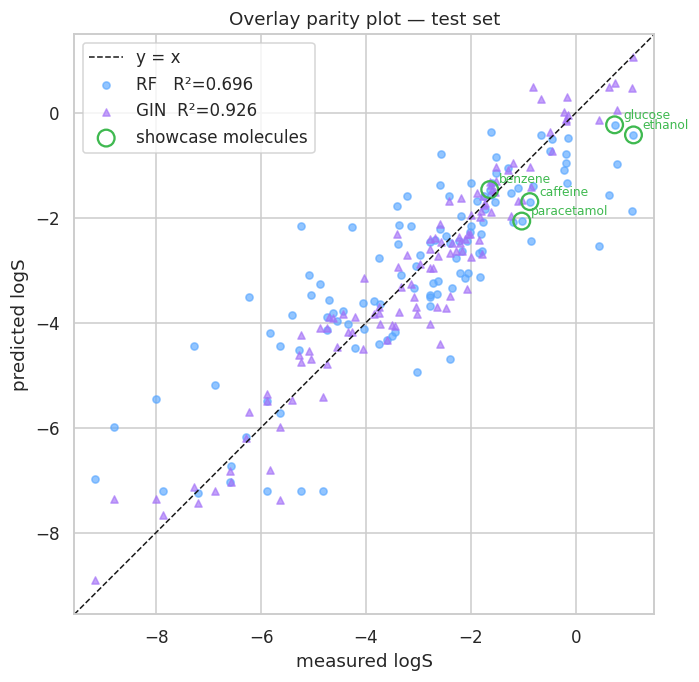

In [21]:
comparison = pd.DataFrame({"Random Forest": rf_perf, "Graph Neural Net": gnn_perf}).T[["rmse", "mae", "r2"]].round(3)
comparison.columns = ["RMSE", "MAE", "R²"]
display(comparison)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
lim = [y_test.min() - 0.4, y_test.max() + 0.4]
ax.plot(lim, lim, "k--", lw=1, label="y = x")
ax.scatter(y_test, rf_test_pred, s=22, alpha=0.65, color="#58a6ff", label=f"RF   R²={rf_perf['r2']:.3f}")
ax.scatter(y_test, gnn_test_pred, s=22, alpha=0.65, color="#a371f7", marker="^", label=f"GIN  R²={gnn_perf['r2']:.3f}")
sc = pd.DataFrame(predictions).query("showcase and actual_source == 'dataset'")
ax.scatter(sc["actual"], sc["rf_pred"], s=120, facecolor="none", edgecolor="#3fb950", lw=1.5, label="showcase molecules")
for r in sc.itertuples(): ax.annotate(r.name, (r.actual, r.rf_pred), textcoords="offset points", xytext=(6, 4), fontsize=8, color="#3fb950")
ax.set(xlim=lim, ylim=lim, xlabel="measured logS", ylabel="predicted logS", title="Overlay parity plot — test set"); ax.set_aspect("equal"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "overlay_parity.png"); plt.show()

In [22]:
# Where do the models disagree most, and does uncertainty know it?
res = pd.DataFrame(predictions)
res["rf_err"], res["gnn_err"] = (res.rf_pred - res.actual).abs(), (res.gnn_pred - res.actual).abs()
print("Spearman(|error|, std):  RF %.2f   GNN %.2f" % (res[["rf_err", "rf_std"]].corr("spearman").iloc[0, 1], res[["gnn_err", "gnn_std"]].corr("spearman").iloc[0, 1]))
res.sort_values("rf_err", ascending=False)[["name", "actual", "rf_pred", "gnn_pred", "rf_err", "gnn_err", "rf_std", "gnn_std"]].head(10).round(3)

Spearman(|error|, std):  RF 0.22   GNN 0.01


,name,actual,rf_pred,gnn_pred,rf_err,gnn_err,rf_std,gnn_std
107,Hexamethylbenzene,-5.230,-2.166,-4.226,3.064,1.004,1.053,0.232
26,"2,6-Dimethylpyridine",0.450,-2.532,-0.136,2.982,0.586,1.139,0.393
11,2-pyrrolidone,1.070,-1.868,0.478,2.938,0.592,1.285,0.285
54,Dienochlor,-7.278,-4.437,-7.139,2.841,0.139,1.653,0.531
32,Perylene,-8.804,-5.986,-7.366,2.818,1.438,2.143,0.445
118,Abate,-6.237,-3.518,-5.698,2.719,0.539,1.194,0.393
60,Fluvalinate,-8.003,-5.454,-7.366,2.549,0.637,2.096,0.418
0,water,1.740,-0.716,2.340,2.456,0.600,0.691,0.437
13,1-Iodoheptane,-4.810,-7.206,-5.417,2.396,0.607,1.038,0.261
55,1-Octanol,-2.390,-4.691,-2.668,2.301,0.278,0.821,0.217


### Interpretation

* **The GNN wins clearly** (seed 42: GIN R² ≈ 0.93 / RMSE ≈ 0.58 vs RF R² ≈ 0.70 / RMSE ≈ 1.18 on the 116-molecule test set — the table above holds the exact numbers from this run). The GIN's RMSE is in the range of the original ESOL linear model (~0.6–0.7) and of published fingerprint-free deep models.
* **Why the fingerprint RF struggles here.** A 2048-bit *binary* Morgan fingerprint records *which* local environments are present, not *how many* or *how big the molecule is*. Solubility is dominated by exactly those global quantities (size, total aromatic surface, number of polar groups). Look at the worst RF errors above: hexamethylbenzene (six methyls, but the same two bits as toluene), 1-octanol vs 1-decanol (identical fingerprints beyond radius 2), tiny polar heterocycles (2-pyrrolidone, 2,6-dimethylpyridine) with no close training neighbours. The RF can only average labels of training molecules with similar bit patterns, so its predictions compress toward the mean (the flattening at both ends of the RF parity plot).
* **Why the GNN does not.** Message passing propagates information across the whole graph and mean pooling produces a representation that varies smoothly with composition, so size and polarity effects are learned rather than hashed away. With edge features it also distinguishes aromatic from aliphatic rings explicitly.
* **The RF's edge** is practicality and transparency: a full grid search ran in seconds, no GPU, and every prediction decomposes into Shapley contributions of nameable substructures. The SHAP table recovers textbook chemistry: aromatic carbons, aryl chlorides and long alkyl chains push `logS` down; carbonyl carbons and oxygen atoms push it up.
* **Uncertainty is heuristic.** Tree variance (RF) ranks errors modestly (Spearman ≈ 0.2); MC-dropout std is nearly uninformative for this small network (Spearman ≈ 0). Neither is a calibrated interval. The frontend shows ±std so this limitation is visible, not hidden.
* **Caveats.** 1 115 molecules is a small dataset and a single random split; R² can move by several hundredths across splits. Literature `logS` values for the five showcase molecules absent from ESOL come from different experimental protocols than ESOL's, so their errors are only indicative.

Open `index.html` to explore the test-set predictions, the 3D conformers and the extra property tabs interactively.

## 7. Auto-generate README.md

The README is rendered from `export_results.json` and the SHAP bit table, so every number in it is a real result of this run.

In [23]:
E = json.loads(Path("export_results.json").read_text())
rfp, gp = E["model_perf"]["rf"], E["model_perf"]["gnn"]
winner, loser = ("GNN", "RF") if gp["r2"] > rfp["r2"] else ("RF", "GNN")
P = pd.DataFrame(E["predictions"]).query("showcase").copy()
P["rf_err"], P["gnn_err"] = (P.rf_pred - P.actual).abs(), (P.gnn_pred - P.actual).abs()
P = P.sort_values("rf_err", ascending=False)

rows = "\n".join(f"| {r.name} | {r.actual:.2f}{'' if r.actual_source == 'dataset' else ' †'} | {r.rf_pred:.2f} | {r.gnn_pred:.2f} | {r.rf_err:.2f} | {r.gnn_err:.2f} |" for r in P.itertuples())
down = ", ".join(f"`{b.fragment}`" for b in bit_table.itertuples() if "↓" in b.direction)[:200]
up   = ", ".join(f"`{b.fragment}`" for b in bit_table.itertuples() if "↑" in b.direction)[:200]

readme = f'''# Molecular Property Prediction
## RF vs GNN on the Delaney ESOL Dataset

### Overview
This project predicts aqueous solubility (logS, log mol/L) for small organic molecules from their structure alone, using two fundamentally different representations: a classical **Morgan-fingerprint + Random Forest** baseline and a **graph neural network (GIN)** that learns directly from the molecular graph. Both are trained and evaluated on identical splits of the Delaney ESOL dataset ({E["meta"]["n_total"]} molecules; {E["meta"]["n_train"]} train / {E["meta"]["n_val"]} val / {E["meta"]["n_test"]} test), and the results drive an interactive 3D dashboard.

### Demo
> Open `index.html` in any browser — no server required. (The page reads `export_results.json` / `coords.json` when served over HTTP and falls back to embedded data when opened as a file.)

![UI preview](preview.png)

### Methods
- **Approach A — Morgan Fingerprints + Random Forest.** Each molecule is encoded as a 2048-bit Morgan/ECFP4 fingerprint (radius 2) with RDKit. A `RandomForestRegressor` is tuned with 3-fold `GridSearchCV` over `n_estimators`, `max_features` and `min_samples_leaf` (selected: {E["meta"]["rf_params"]}). Prediction uncertainty is the standard deviation across trees; explanations come from SHAP `TreeExplainer`.
- **Approach B — Graph Neural Network (GIN).** Atoms become nodes (37-dim features: element, degree, hybridisation, aromaticity, formal charge, attached H count) and bonds become edges (6-dim: bond type, conjugation, ring membership). Three `GINEConv` layers with residual connections and BatchNorm, global mean pooling and a 3-layer MLP head ({E["meta"]["gnn"]["hidden"]} hidden units, dropout {E["meta"]["gnn"]["dropout"]}). Trained with Adam + `ReduceLROnPlateau` and early stopping on validation RMSE (best epoch {E["meta"]["gnn"]["best_epoch"]}); uncertainty from 30-sample Monte-Carlo dropout. CPU only.

### Results
Held-out test set, {E["meta"]["n_test"]} molecules:

| Metric | Random Forest | Graph Neural Net |
|--------|--------------|-----------------|
| RMSE   | {rfp["rmse"]:.3f} | {gp["rmse"]:.3f} |
| MAE    | {rfp["mae"]:.3f} | {gp["mae"]:.3f} |
| R²     | {rfp["r2"]:.3f} | {gp["r2"]:.3f} |

The {winner} outperforms the {loser} on R² ({max(gp["r2"], rfp["r2"]):.2f} vs {min(gp["r2"], rfp["r2"]):.2f}): binary fingerprints record *which* substructures are present but not molecular size or how many polar groups there are, which is exactly what drives solubility, whereas message passing over the full graph captures these global patterns. The RF, however, trains in seconds, needs no GPU and offers full SHAP explainability.

A secondary target (RDKit Crippen logP, same splits and architectures) gives RF R² {E["model_perf_logp"]["rf"]["r2"]:.3f} vs GNN R² {E["model_perf_logp"]["gnn"]["r2"]:.3f}; these predictions power the *Lipophilicity* tab of the dashboard.

### Per-molecule Predictions
Showcase molecules, sorted by |RF error| descending (full test set of {len(E["predictions"])} molecules in `export_results.json`):

| Molecule | Actual logS | RF pred | GNN pred | RF err | GNN err |
|----------|------------|---------|---------|--------|---------|
{rows}

† literature value (molecule not in ESOL); all others are ESOL measurements and were held out of training.

### Explainability
SHAP (`TreeExplainer`, interventional) on the RF shows that the Morgan bits with the largest impact on predicted solubility encode aromatic carbons, aryl chlorides and aliphatic chain carbons — all pushing logS **down** ({down}) — while carbonyl carbons and oxygen-centred environments push it **up** ({up}). This matches the chemical intuition that hydrophobic surface area lowers solubility and hydrogen-bonding groups raise it. See `figures/shap_beeswarm.png` and `figures/shap_top_bits.png`.

### Project Structure
```
molecular-prediction/
├── requirements.txt       # pip dependencies
├── notebook.ipynb         # full ML pipeline (EDA → RF → GNN → export → README)
├── export_results.json    # metrics + per-molecule predictions (generated)
├── coords.json            # RDKit 3D coordinates for every exported molecule (generated)
├── index.html             # standalone interactive frontend (Three.js + Chart.js)
├── README.md              # this file (generated)
├── preview.png            # screenshot of index.html
├── data/                  # delaney-processed.csv (downloaded on first run)
└── figures/               # plots saved by the notebook
```

### Setup
```bash
pip install -r requirements.txt
jupyter notebook notebook.ipynb      # run all cells (~1 min on CPU)
# then open index.html, or: python -m http.server  →  http://localhost:8000
```

### Tech Stack
Python · RDKit · scikit-learn · PyTorch Geometric · Three.js · Chart.js · SHAP

---
*Generated automatically from export_results.json on {date.today().isoformat()}.*
'''
Path("README.md").write_text(readme)
print(readme[:1200], "...")

# Molecular Property Prediction
## RF vs GNN on the Delaney ESOL Dataset

### Overview
This project predicts aqueous solubility (logS, log mol/L) for small organic molecules from their structure alone, using two fundamentally different representations: a classical **Morgan-fingerprint + Random Forest** baseline and a **graph neural network (GIN)** that learns directly from the molecular graph. Both are trained and evaluated on identical splits of the Delaney ESOL dataset (1115 molecules; 888 train / 111 val / 116 test), and the results drive an interactive 3D dashboard.

### Demo
> Open `index.html` in any browser — no server required. (The page reads `export_results.json` / `coords.json` when served over HTTP and falls back to embedded data when opened as a file.)

![UI preview](preview.png)

### Methods
- **Approach A — Morgan Fingerprints + Random Forest.** Each molecule is encoded as a 2048-bit Morgan/ECFP4 fingerprint (radius 2) with RDKit. A `RandomForestRegressor` is tuned with 